# La población de glóbulos rojos

Sea $x_n$ el número de glóbulos rojos en el cuerpo el día $n$. Cada día se destruye una fracción constante $c$ de ellos y la médula ósea produce $p(x_n)$ células nuevas:

$$
x_{n+1} = x_n - c\,x_n + p(x_n) \;=\; (1 - c)\,x_n + p(x_n).
$$

La producción está regulada: cuando hay pocos glóbulos rojos (anemia, falta de oxígeno) la médula produce más, y cuando hay muchos produce menos. El enunciado propone dos formas para $p$:

$$
p_1(x) = a\,x\,e^{-b x}\quad (a, b > 0),
\qquad\qquad
p_2(x) = \frac{b\,\theta^m\,x}{\theta^m + x^m}\quad (b, \theta, m > 0).
$$

**Contenido**

1. Qué significan los parámetros de $p_1$ y $p_2$.
2. Comportamiento a largo plazo: equilibrios, estabilidad, comparación de $p(x)$ con $d(x) = c x$ y diagramas de bifurcación.
3. Un retraso en la producción.
4. Comparación con el modelo de Tetschke et al. (2018).
5. Parámetros del artículo traducidos a nuestro modelo: recuperación después de una donación.

In [1]:
# ============================================================
# Bibliotecas
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})


# ============================================================
# Funciones de producción
# ============================================================
def p1(x, a, b):
    """Producción tipo Ricker: p1(x) = a x exp(-b x)."""
    return a * x * np.exp(-b * x)


def p2(x, b, theta, m):
    """Producción tipo Hill: p2(x) = b theta^m x / (theta^m + x^m)."""
    return b * theta**m * x / (theta**m + x**m)


def iterar(f, x0, n_pasos):
    """
    Itera el mapeo x_{n+1} = f(x_n) a partir de x0.
    Regresa un arreglo con x_0, x_1, ..., x_{n_pasos}.
    """
    x = np.empty(n_pasos + 1)
    x[0] = x0
    for n in range(n_pasos):
        x[n + 1] = f(x[n])
    return x

## 1. ¿Qué significan los parámetros?

Una forma útil de leer cada función es separarla en "número de células" por "producción **por célula**": $p(x) = x\cdot g(x)$, con $g$ la producción per cápita.

**Ricker, $p_1(x) = a x e^{-bx}$.** Aquí $g(x) = a e^{-bx}$.

* $a = p_1'(0)$ es la producción por célula cuando hay muy pocas: la **ganancia máxima** de la médula. Si $a$ es grande, la médula responde con fuerza a la anemia.
* $b$ mide la **sensibilidad a la abundancia**: la producción per cápita cae a la mitad cada vez que $x$ aumenta en $\ln 2/b$. La producción total es máxima en $x = 1/b$ y ahí vale $a/(b e)$. Si $b$ es pequeño la producción sigue creciendo hasta poblaciones grandes; si $b$ es grande, la médula "se apaga" con pocas células.
* Para $x$ grande la producción decae exponencialmente: con exceso de glóbulos rojos la producción prácticamente se detiene.

**Hill, $p_2(x) = \dfrac{b\theta^m x}{\theta^m + x^m}$.** Aquí $g(x) = \dfrac{b\theta^m}{\theta^m + x^m}$.

* $b = p_2'(0)$ es, igual que antes, la producción por célula cuando hay muy pocas.
* $\theta$ es un **umbral**: en $x = \theta$ la producción per cápita es exactamente la mitad de la máxima, $b/2$.
* $m$ controla **qué tan abrupta** es la regulación. Si $m \le 1$, $p_2$ es creciente (con $m = 1$ se satura en $b\theta$). Si $m > 1$, $p_2$ tiene un máximo en $x = \theta(m-1)^{1/m}$ y luego decrece como $x^{1-m}$. Con $m$ muy grande la regulación es casi un interruptor: producción per cápita $b$ si $x<\theta$ y casi cero si $x>\theta$.

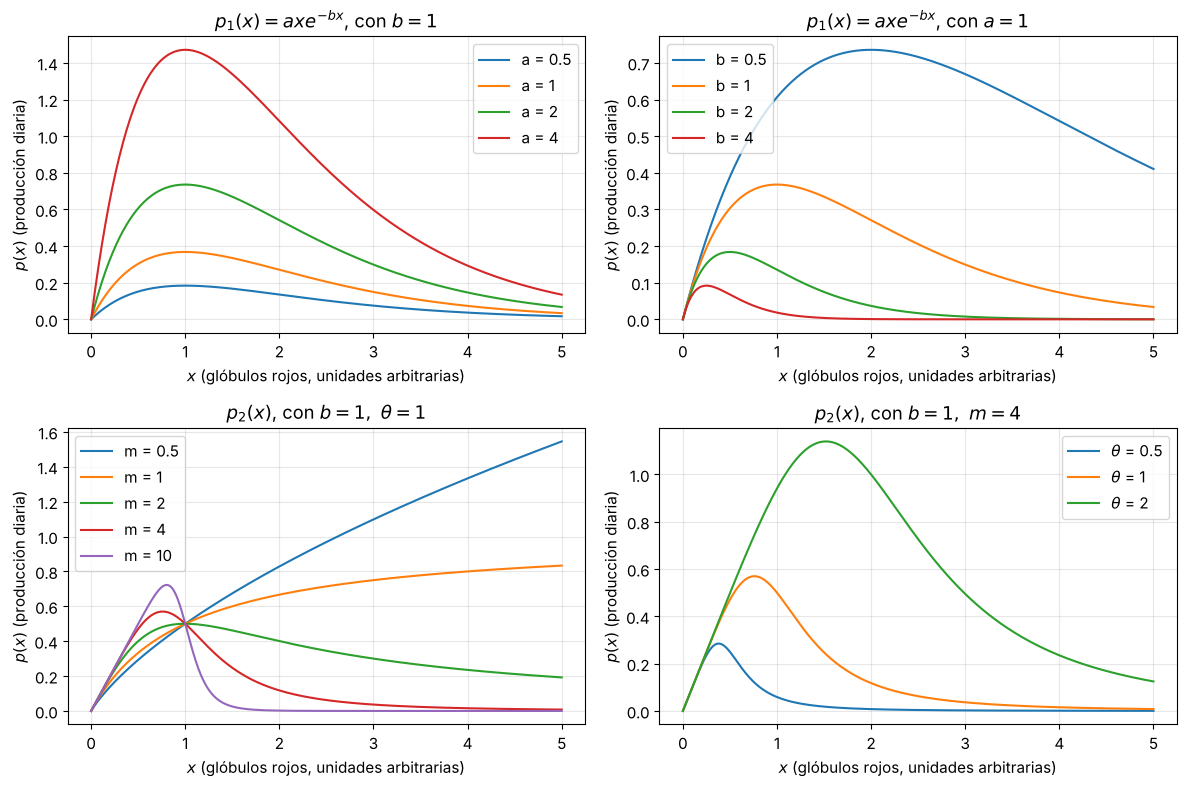

In [2]:
x = np.linspace(0, 5, 400)
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# p1: variamos a con b fijo, y b con a fijo.
for a in [0.5, 1, 2, 4]:
    axs[0, 0].plot(x, p1(x, a, 1.0), label=f"a = {a}")
axs[0, 0].set_title(r"$p_1(x) = a x e^{-bx}$, con $b = 1$")
for b in [0.5, 1, 2, 4]:
    axs[0, 1].plot(x, p1(x, 1.0, b), label=f"b = {b}")
axs[0, 1].set_title(r"$p_1(x) = a x e^{-bx}$, con $a = 1$")

# p2: variamos m con b, theta fijos, y theta con b, m fijos.
for m in [0.5, 1, 2, 4, 10]:
    axs[1, 0].plot(x, p2(x, 1.0, 1.0, m), label=f"m = {m}")
axs[1, 0].set_title(r"$p_2(x)$, con $b = 1,\ \theta = 1$")
for theta in [0.5, 1, 2]:
    axs[1, 1].plot(x, p2(x, 1.0, theta, 4), label=rf"$\theta$ = {theta}")
axs[1, 1].set_title(r"$p_2(x)$, con $b = 1,\ m = 4$")

for ax in axs.flat:
    ax.set_xlabel("$x$ (glóbulos rojos, unidades arbitrarias)")
    ax.set_ylabel("$p(x)$ (producción diaria)")
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Comportamiento a largo plazo

### Equilibrios: $p(x)$ contra $d(x)$

Un equilibrio $x^{\ast}$ cumple $x^{\ast} = (1-c)x^{\ast} + p(x^{\ast})$, es decir

$$
p(x^{\ast}) = d(x^{\ast}) = c\,x^{\ast}:
$$

**lo que se produce es igual a lo que se destruye.** Gráficamente, los equilibrios son las intersecciones de la curva $p(x)$ con la recta $d(x) = cx$. Siempre está $x^{\ast} = 0$. Si $p$ está por encima de $d$ la población crece; si está por debajo, decrece.

* Para $p_1$: $a e^{-bx^{\ast}} = c$, así que $x^{\ast} = \dfrac{1}{b}\ln\dfrac{a}{c}$, que existe (es positivo) si $a > c$.
* Para $p_2$: $\dfrac{b\theta^m}{\theta^m + (x^{\ast})^m} = c$, así que $x^{\ast} = \theta\left(\dfrac{b}{c} - 1\right)^{1/m}$, que existe si $b > c$.

En ambos casos la condición tiene una lectura clara: **la producción por célula en anemia extrema debe superar la tasa de destrucción**; si no, la población se extingue ($x^{\ast} = 0$ es el único equilibrio y es estable).

### Estabilidad

Escribimos $f(x) = (1-c)x + p(x)$. Un equilibrio de un mapeo es estable si $\lvert f'(x^{\ast})\rvert < 1$, con $f'(x^{\ast}) = 1 - c + p'(x^{\ast})$. Haciendo las cuentas:

* **Ricker:** $p_1'(x) = a e^{-bx}(1 - bx)$. En el equilibrio $a e^{-bx^{\ast}} = c$ y $b x^{\ast} = \ln(a/c)$, de modo que

$$
f'(x^{\ast}) = 1 - c\,\ln\frac{a}{c}.
$$

* **Hill:** derivando, $p_2'(x) = b\theta^m\dfrac{\theta^m + (1-m)x^m}{(\theta^m + x^m)^2}$, y usando $\theta^m + (x^{\ast})^m = b\theta^m/c$ y $(x^{\ast})^m = \theta^m(b/c - 1)$ se simplifica a

$$
f'(x^{\ast}) = 1 - c\,m\left(1 - \frac{c}{b}\right).
$$

En los dos casos $f'(x^{\ast}) < 1$ siempre (cuando el equilibrio existe), así que la única forma de perder la estabilidad es que $f'(x^{\ast}) < -1$:

$$
\text{Ricker: } c\ln\frac{a}{c} > 2, \qquad \text{Hill: } c\,m\left(1 - \frac{c}{b}\right) > 2 .
$$

Cuando eso ocurre, el sistema **se pasa** del equilibrio cada día y oscila: es una bifurcación de **duplicación de periodo**, que al seguir aumentando el parámetro lleva al caos. Geométricamente, sucede cuando $p(x)$ cruza a $d(x)$ con una pendiente muy negativa ($p'(x^{\ast}) < c - 2$): la médula corrige "demasiado" y demasiado rápido. Si $0 < f'(x^{\ast}) < 1$ la aproximación al equilibrio es monótona, y si $-1 < f'(x^{\ast}) < 0$ es con oscilaciones amortiguadas.

**¿Qué pasa con valores realistas?** Un glóbulo rojo vive unos 120 días, así que $c \approx 1/120 \approx 0.0083$ por día. Para Hill, la inestabilidad requiere $m > 2/c \approx 240$, y para Ricker $\ln(a/c) > 240$. **Con la vida media real de los glóbulos rojos, este modelo sin retraso es enormemente estable.** Para ver la dinámica interesante en las figuras usamos valores de $c$ grandes, y en la sección 3 veremos que lo que sí desestabiliza es el retraso.

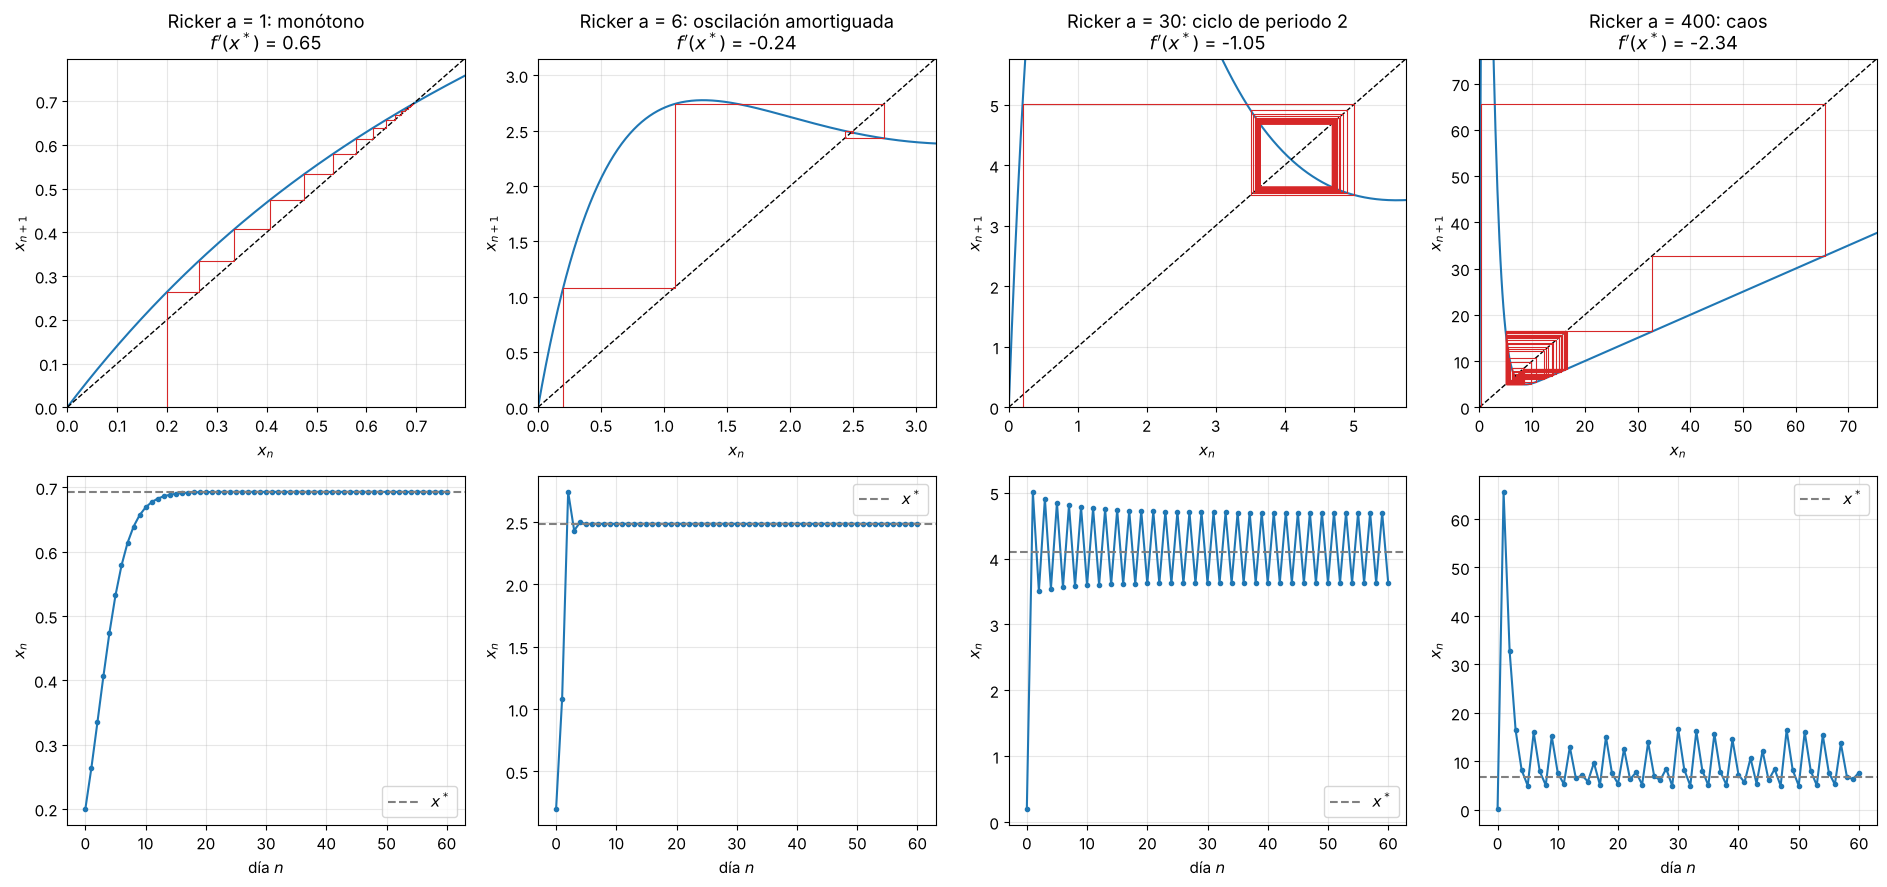

In [3]:
def telarania(ax, f, x0, n_pasos, xmax, titulo):
    """
    Dibuja el diagrama de telaraña (cobweb) del mapeo f desde x0:
    la curva y = f(x), la diagonal y = x y la trayectoria escalonada.
    """
    xs = np.linspace(0, xmax, 400)
    ax.plot(xs, f(xs), "C0", label="$f(x)$")
    ax.plot(xs, xs, "k--", lw=1, label="$y = x$")
    tray = iterar(f, x0, n_pasos)
    # Cada paso: vertical hasta la curva, horizontal hasta la diagonal.
    px, py = [tray[0]], [0]
    for n in range(n_pasos):
        px += [tray[n], tray[n + 1]]
        py += [tray[n + 1], tray[n + 1]]
    ax.plot(px, py, "C3", lw=0.8)
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, xmax)
    ax.set_title(titulo)
    ax.set_xlabel("$x_n$")
    ax.set_ylabel("$x_{n+1}$")


fig, axs = plt.subplots(2, 4, figsize=(19, 9))
c = 0.5   # tasa de destrucción GRANDE (didáctica) para ver todos los regímenes
casos = [  # (a, descripción) para Ricker con b = 1
    (1.0, "monótono"), (6.0, "oscilación amortiguada"),
    (30.0, "ciclo de periodo 2"), (400.0, "caos")]
for k, (a, desc) in enumerate(casos):
    f = lambda x, a=a: (1 - c) * x + p1(x, a, 1.0)
    fp = 1 - c * np.log(a / c)                       # f'(x*) teórica
    xmax = 1.15 * iterar(f, 0.2, 60).max()           # ventana que contenga la órbita
    telarania(axs[0, k], f, 0.2, 60, xmax,
              f"Ricker a = {a:g}: {desc}\n$f'(x^*)$ = {fp:.2f}")
    axs[1, k].plot(iterar(f, 0.2, 60), "o-", ms=3)
    axs[1, k].axhline(np.log(a / c), color="gray", ls="--", label="$x^*$")
    axs[1, k].set_xlabel("día $n$")
    axs[1, k].set_ylabel("$x_n$")
    axs[1, k].legend()
plt.tight_layout()
plt.show()

m =  1: x* = 1.000, f'(x*) = +0.75 -> estable
m =  4: x* = 1.000, f'(x*) = +0.00 -> estable
m =  6: x* = 1.000, f'(x*) = -0.50 -> estable
m = 10: x* = 1.000, f'(x*) = -1.50 -> INESTABLE


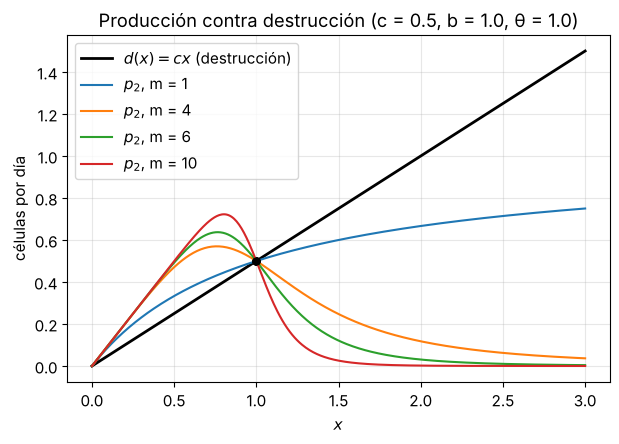

In [4]:
# Comparación gráfica de p(x) con d(x) = c x para p2 y distintos m.
# Las intersecciones son los equilibrios; la pendiente de p en la
# intersección decide la estabilidad.
c, b, theta = 0.5, 1.0, 1.0
x = np.linspace(0, 3, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x, c * x, "k", lw=2, label="$d(x) = cx$ (destrucción)")
for m in [1, 4, 6, 10]:
    ax.plot(x, p2(x, b, theta, m), label=f"$p_2$, m = {m}")
    xe = theta * (b / c - 1) ** (1 / m)
    ax.plot(xe, c * xe, "ko", ms=5)
    print(f"m = {m:2d}: x* = {xe:.3f}, f'(x*) = {1 - c * m * (1 - c / b):+.2f}",
          "-> estable" if abs(1 - c * m * (1 - c / b)) < 1 else "-> INESTABLE")
ax.set_xlabel("$x$")
ax.set_ylabel("células por día")
ax.set_title(f"Producción contra destrucción (c = {c}, b = {b}, θ = {theta})")
ax.legend()
plt.show()

### Diagramas de bifurcación

Para cada valor del parámetro iteramos el mapeo muchas veces, descartamos el transitorio y graficamos los valores que visita a largo plazo. Un punto por valor del parámetro significa un equilibrio estable; dos, un ciclo de periodo 2; una nube, caos. La línea vertical marca el valor teórico de la primera duplicación de periodo.

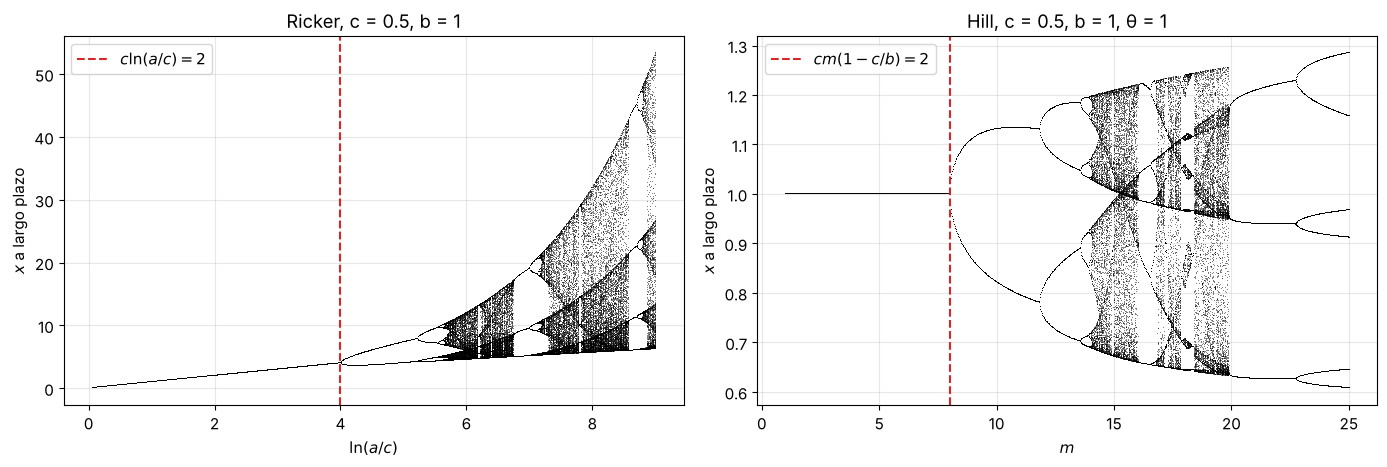

In [5]:
def diagrama_bifurcacion(ax, mapeo, parametros, x0=0.5, transitorio=1000, guardar=150):
    """
    Para cada valor `q` en `parametros` itera x_{n+1} = mapeo(x_n, q),
    descarta `transitorio` pasos y grafica los siguientes `guardar` valores.
    """
    for q in parametros:
        xq = x0
        for _ in range(transitorio):
            xq = mapeo(xq, q)
        visitados = np.empty(guardar)
        for i in range(guardar):
            xq = mapeo(xq, q)
            visitados[i] = xq
        ax.plot(np.full(guardar, q), visitados, ",k", alpha=0.5)


fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
c = 0.5

# Ricker con b = 1; graficamos contra ln(a/c) para que el umbral sea c ln(a/c) = 2.
lns = np.linspace(0.05, 9, 900)
diagrama_bifurcacion(axs[0], lambda x, L: (1 - c) * x + p1(x, c * np.exp(L), 1.0), lns)
axs[0].axvline(2 / c, color="C3", ls="--", label=r"$c\ln(a/c) = 2$")
axs[0].set_xlabel(r"$\ln(a/c)$")
axs[0].set_ylabel("$x$ a largo plazo")
axs[0].set_title(f"Ricker, c = {c}, b = 1")
axs[0].legend()

# Hill con b = 1, theta = 1, variando m.
ms = np.linspace(1, 25, 900)
diagrama_bifurcacion(axs[1], lambda x, m: (1 - c) * x + p2(x, 1.0, 1.0, m), ms)
axs[1].axvline(2 / (c * (1 - c / 1.0)), color="C3", ls="--", label=r"$cm(1-c/b) = 2$")
axs[1].set_xlabel("$m$")
axs[1].set_ylabel("$x$ a largo plazo")
axs[1].set_title(f"Hill, c = {c}, b = 1, θ = 1")
axs[1].legend()
plt.tight_layout()
plt.show()

**Resumen de la sección.** A largo plazo, la población se va a cero si la médula no alcanza a reponer lo destruido ($a \le c$ o $b \le c$). Si sí alcanza, existe un equilibrio positivo cuyo valor está fijado por $b$ (Ricker) o por $\theta$, $m$ y $b/c$ (Hill). Que el equilibrio sea estable depende de **qué tan abrupta** sea la regulación cerca de él ($a$ grande en Ricker, $m$ grande en Hill): si la médula corrige con demasiada fuerza, aparecen oscilaciones y caos. Con la vida media real de los glóbulos rojos esto no ocurre en el modelo sin retraso.

## 3. Un retraso en la producción

Un glóbulo rojo tarda varios días en formarse: desde que la médula "decide" producir (en respuesta a la eritropoyetina) hasta que el reticulocito sale a la sangre pasan alrededor de 5 a 7 días. La forma más sencilla de incluirlo es que la producción de hoy dependa de la población de hace $k$ días:

$$
x_{n+1} = (1 - c)\,x_n + p(x_{n-k}).
$$

Ahora hay que dar como condición inicial los $k+1$ valores $x_0, x_{-1}, \dots, x_{-k}$. Es la versión discreta de la ecuación con retraso de **Mackey y Glass (1977)**, $\dot P = \beta_0\theta^n P(t-\tau)/(\theta^n + P(t-\tau)^n) - \gamma P$, que propusieron justamente para explicar oscilaciones en enfermedades de la sangre.

**Linealización.** Cerca del equilibrio, con $u_n = x_n - x^{\ast}$ y $\beta = p'(x^{\ast})$:

$$
u_{n+1} = (1-c)\,u_n + \beta\,u_{n-k}.
$$

Buscando soluciones $u_n = \lambda^n$ se obtiene el polinomio característico

$$
\lambda^{k+1} - (1-c)\,\lambda^k - \beta = 0 ,
$$

y el equilibrio es estable si **todas** sus raíces cumplen $\lvert\lambda\rvert < 1$. Las raíces se calculan numéricamente con `numpy.roots`.

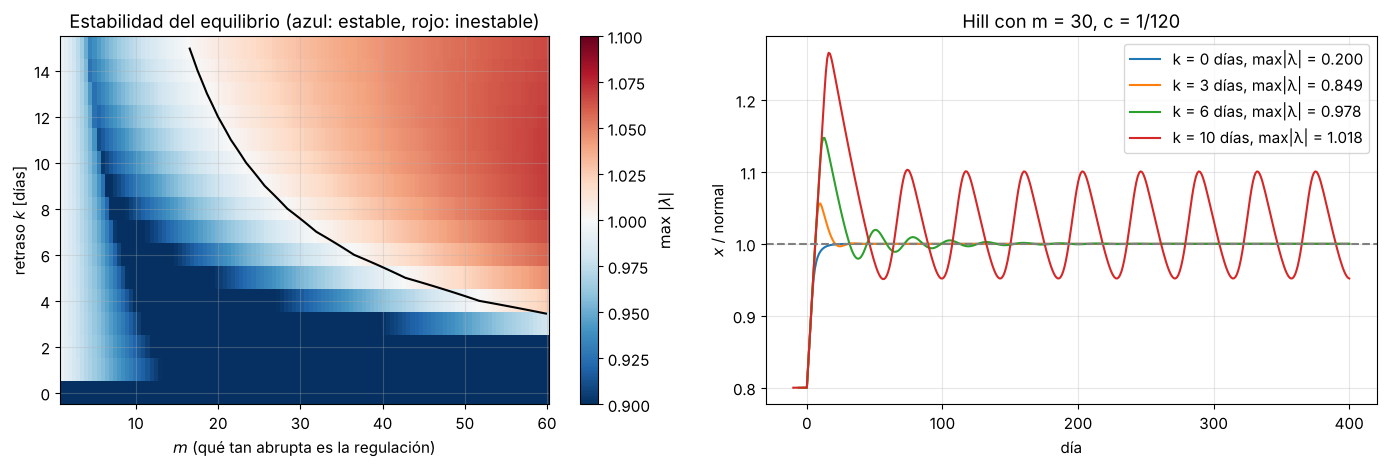

In [6]:
def iterar_con_retraso(c, p, k, historia, n_pasos):
    """
    Itera x_{n+1} = (1 - c) x_n + p(x_{n-k}).

    Parámetros
    ----------
    c : tasa de destrucción diaria.
    p : función de producción p(x).
    k : retraso en días (k = 0 recupera el modelo original).
    historia : arreglo con los k+1 valores iniciales [x_{-k}, ..., x_{-1}, x_0].
    n_pasos : número de días a simular.

    Regresa x_{-k}, ..., x_{n_pasos} (los primeros k+1 son la historia).
    """
    x = np.empty(k + 1 + n_pasos)
    x[:k + 1] = historia
    for n in range(k, k + n_pasos):
        x[n + 1] = (1 - c) * x[n] + p(x[n - k])
    return x


def radio_espectral(c, beta, k):
    """Máximo |lambda| de lambda^{k+1} - (1-c) lambda^k - beta = 0."""
    coef = np.zeros(k + 2)
    coef[0] = 1.0          # lambda^{k+1}
    coef[1] = -(1 - c)     # lambda^{k}
    coef[-1] = -beta       # término independiente
    return np.max(np.abs(np.roots(coef)))


# Valores fisiológicos normalizados: x medido en unidades del equilibrio
# (x* = 1). Destrucción c = 1/120 por día; la médula puede producir hasta
# b = 6c por célula en anemia extrema (supuesto); theta se elige para que
# el equilibrio sea x* = 1.
c = 1 / 120
b = 6 * c


def theta_para_equilibrio_1(m):
    """theta tal que x* = theta (b/c - 1)^{1/m} = 1."""
    return (b / c - 1) ** (-1 / m)


def beta_hill(m):
    """p2'(x*) = c (1 - m (1 - c/b)), de la sección 2."""
    return c * (1 - m * (1 - c / b))


# Mapa de estabilidad en el plano (m, k).
m_vals = np.linspace(1, 60, 120)
k_vals = np.arange(0, 16)
R = np.array([[radio_espectral(c, beta_hill(m), k) for m in m_vals] for k in k_vals])

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
im = axs[0].pcolormesh(m_vals, k_vals, R, cmap="RdBu_r", vmin=0.9, vmax=1.1, shading="auto")
axs[0].contour(m_vals, k_vals, R, levels=[1.0], colors="k")
plt.colorbar(im, ax=axs[0], label=r"$\max\,|\lambda|$")
axs[0].set_xlabel("$m$ (qué tan abrupta es la regulación)")
axs[0].set_ylabel("retraso $k$ [días]")
axs[0].set_title("Estabilidad del equilibrio (azul: estable, rojo: inestable)")

# Simulaciones: con m = 30 y retrasos de 0, 3, 6 y 10 días,
# partiendo de una anemia (x = 0.8 del normal).
m = 30.0
p = lambda x: p2(x, b, theta_para_equilibrio_1(m), m)
for k in [0, 3, 6, 10]:
    tray = iterar_con_retraso(c, p, k, np.full(k + 1, 0.8), 400)
    axs[1].plot(np.arange(-k, 401), tray,
                label=f"k = {k} días, max|λ| = {radio_espectral(c, beta_hill(m), k):.3f}")
axs[1].axhline(1, color="gray", ls="--")
axs[1].set_xlabel("día")
axs[1].set_ylabel("$x$ / normal")
axs[1].set_title(f"Hill con m = {m:.0f}, c = 1/120")
axs[1].legend()
plt.tight_layout()
plt.show()

**Lectura.** Sin retraso, incluso con $m = 30$ la población vuelve al equilibrio sin oscilar. Con un retraso de 3 a 6 días aparecen sobrepasos y oscilaciones amortiguadas; con 10 días de retraso el equilibrio ya es inestable (región roja del mapa) y las oscilaciones se vuelven **sostenidas**: la médula responde a una anemia "vieja" y, cuando la producción por fin llega, la población ya se recuperó y sobrepasa el equilibrio. Este es el mecanismo que Mackey y Glass propusieron para enfermedades con oscilaciones periódicas en el conteo de células sanguíneas.

Otra observación: en el polinomio característico, una $c$ mayor (más destrucción, como en una anemia hemolítica) hace más fácil la inestabilidad. Lo comprobamos rápidamente:

In [7]:
# Para k = 6 días, ¿qué m hace falta para la inestabilidad según la tasa de destrucción?
for vida_media in [120, 60, 30, 15]:
    c_q = 1 / vida_media
    b_q = 6 * c_q
    beta = lambda m: c_q * (1 - m * (1 - c_q / b_q))
    ms_fino = np.linspace(1, 400, 4000)
    inestables = [m for m in ms_fino if radio_espectral(c_q, beta(m), 6) > 1]
    m_crit = inestables[0] if inestables else np.nan
    print(f"vida media {vida_media:3d} días (c = {c_q:.4f}): inestable para m > {m_crit:.1f}")

vida media 120 días (c = 0.0083): inestable para m > 36.6
vida media  60 días (c = 0.0167): inestable para m > 19.3


vida media  30 días (c = 0.0333): inestable para m > 10.6
vida media  15 días (c = 0.0667): inestable para m > 6.2


## 4. Comparación con Tetschke et al. (2018)

Tetschke, Lilienthal, Pottgiesser, Fischer, Schalk y Sager (2018), *Mathematical Modeling of RBC Count Dynamics after Blood Loss*, Processes 6(9): 157, proponen un modelo **deliberadamente simple** para poder personalizarlo con pocos datos clínicos. Su motivación a largo plazo es planear las sangrías (flebotomías) de pacientes con policitemia vera.

**El modelo.** Tres compartimentos de células en tiempo continuo:

* $x_1$: progenitores que proliferan en respuesta a la eritropoyetina (EPO), como las CFU-E y los primeros eritroblastos. Permanecen en promedio 8 días ($k_1 = 1/8$ día⁻¹).
* $x_2$: precursores que ya no responden a la EPO (eritroblastos tardíos y reticulocitos en la médula). Permanecen en promedio 6 días ($k_2 = 1/6$ día⁻¹).
* $x_3$: eritrocitos (y reticulocitos) en la sangre, que mueren con tasa $\alpha = 1/120$ día⁻¹. En la práctica $x_3$ se mide como **masa total de hemoglobina** (tHb, en gramos), que es proporcional al número de eritrocitos.

$$
\begin{aligned}
\dot x_1 &= \beta\,(X_0 - k_1 x_1) + F_b(x_3)\,x_1,\\
\dot x_2 &= \beta\,(k_1 x_1 - k_2 x_2),\\
\dot x_3 &= \beta\,(k_2 x_2 - \alpha x_3),
\end{aligned}
\qquad
F_b(x_3) = \gamma\,\frac{\mathit{Base} - x_3}{\mathit{Base}} .
$$

Aquí $X_0$ es un flujo constante de células que entran desde las etapas tempranas (BFU-E), $\mathit{Base}$ es el valor normal de $x_3$ de cada persona (su equilibrio), $\beta$ es un factor que acelera o frena toda la maduración y $\gamma$ mide la fuerza de la respuesta a la pérdida de sangre. **La EPO no aparece como variable**: su efecto está resumido en la retroalimentación lineal $F_b$, que hace proliferar más a $x_1$ cuando $x_3$ está por debajo de lo normal. Los autores argumentan que la EPO fluctúa mucho y casi nunca se mide en la clínica, así que un modelo con EPO explícita tendría parámetros imposibles de estimar.

**Datos y parámetros.** Usan las mediciones de tHb de 29 hombres sanos antes y después de donar una unidad de sangre (Pottgiesser et al., 2008), con unas 8 o 9 mediciones por persona. Fijan $k_1$, $k_2$ y $\alpha$ con valores de la literatura y estiman solo $\beta$ y $\gamma$, que distinguen a una persona de otra. Con un modelo de efectos mixtos obtienen valores de población $\beta = 1.02 \pm 0.15$ y $\gamma = 0.46 \pm 0.07$ día⁻¹, con una variabilidad entre personas de más del 40 %. También estiman $\beta$ y $\gamma$ por separado para cada persona; las recuperaciones van de unos 20 a unos 60 días.

**Análisis.** Linealizan alrededor del equilibrio y, con la fórmula de Cardano, encuentran que no hay oscilaciones si $\gamma \le 0.263\,\beta - 0.0003$ y que el equilibrio es estable si $\gamma \le 4.9\,\beta$. Como unas oscilaciones pequeñas son fisiológicamente aceptables, proponen la condición relajada $\gamma \le 0.5\,\beta$.

**Diferencias principales con nuestro modelo:**

| | Modelo del enunciado | Tetschke et al. (2018) |
|---|---|---|
| Tiempo | discreto (días) | continuo (EDO) |
| Variables | una ($x_n$) | tres compartimentos: dos en la médula y uno en la sangre |
| Producción | $p(x_n)$, una función no lineal (Ricker o Hill) | flujo constante $X_0$ más proliferación de $x_1$ amplificada por $F_b$ |
| Regulación | implícita en la forma de $p$ | retroalimentación lineal $F_b$, que actúa sobre las células sensibles a la EPO, no sobre la producción final |
| Retraso | ninguno (o uno fijo de $k$ días si lo añadimos) | distribuido: unos 14 días de tránsito por $x_1$ y $x_2$ |
| Parámetros | genéricos | $k_1$, $k_2$, $\alpha$ fijos; $\beta$, $\gamma$ ajustados a cada persona |
| Variable medida | número de células | masa de hemoglobina (tHb) |

Hay un parecido de fondo: los dos modelos tienen una destrucción lineal de los eritrocitos ($c = \alpha = 1/120$) y una producción que aumenta cuando faltan eritrocitos. La diferencia esencial es **dónde** actúa la regulación y **cuánto tarda** en notarse: en el modelo del enunciado la producción de hoy responde a los eritrocitos de hoy; en el de Tetschke, la respuesta se aplica a células que llegarán a la sangre unas dos semanas después.

Equilibrio (x1, x2, x3) = [ 59.03  44.27 885.42]  (Tabla 1: 59.03, 44.27, 885.42)
población (β = 1.02, γ = 0.46)    : 90 % del déficit en  39.1 días, máximo = 100.68 % -> oscila un poco según la condición (9)
sujeto 02 (β = 0.87, γ = 0.39)    : 90 % del déficit en  46.3 días, máximo = 100.66 % -> oscila un poco según la condición (9)


sujeto 09 (β = 0.89, γ = 0.36)    : 90 % del déficit en  50.0 días, máximo = 100.38 % -> oscila un poco según la condición (9)
sujeto 12 (β = 1.41, γ = 1.00)    : 90 % del déficit en  19.5 días, máximo = 102.46 % -> oscila un poco según la condición (9)
sujeto 20 (β = 2.80, γ = 0.66)    : 90 % del déficit en  26.8 días, máximo = 100.00 % -> sin oscilaciones según la condición (9)


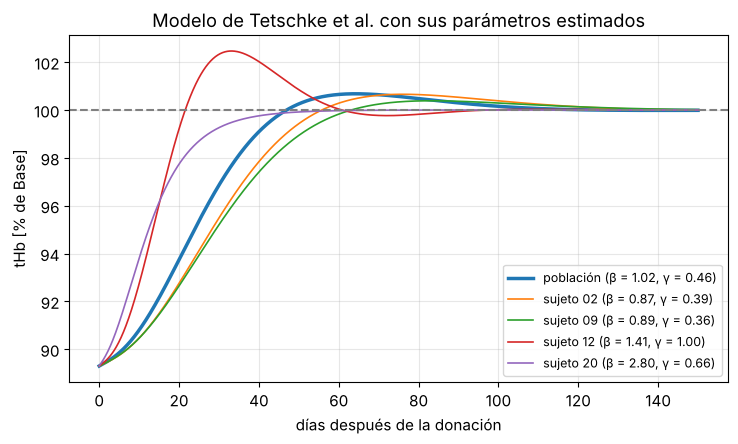

In [8]:
# ============================================================
# El modelo de Tetschke et al. (2018) con sus parámetros
# ============================================================
from scipy.integrate import solve_ivp

K1, K2, ALFA = 1 / 8, 1 / 6, 1 / 120   # tasas de tránsito y de muerte (por día), Tabla 1
# (En la Tabla 1 del artículo alpha aparece con signo negativo; en las ecuaciones (1)
#  es claramente la tasa de muerte positiva 1/120, que es la que usamos.)
BASE = 885.42                           # tHb normal del sujeto ejemplo de la Tabla 1 (g)
X0 = ALFA * BASE                        # flujo de entrada que hace de Base un equilibrio


def tetschke(t, x, beta, gamma):
    """Lado derecho de las ecuaciones (1) del artículo."""
    x1, x2, x3 = x
    Fb = gamma * (BASE - x3) / BASE     # retroalimentación lineal (ecuación 2)
    return [beta * (X0 - K1 * x1) + Fb * x1,
            beta * (K1 * x1 - K2 * x2),
            beta * (K2 * x2 - ALFA * x3)]


equilibrio = np.array([ALFA / K1, ALFA / K2, 1.0]) * BASE      # ecuación (3)
print("Equilibrio (x1, x2, x3) =", np.round(equilibrio, 2), " (Tabla 1: 59.03, 44.27, 885.42)")

# Donación de sangre: en t = 0 se pierde ~10.7 % de x3 (en el artículo, de 885 a ~790 g);
# la médula (x1, x2) no cambia en ese instante.
PERDIDA = 0.107


def recuperacion(beta, gamma, T=150):
    """Integra el modelo después de la donación. Regresa t y x3 / Base."""
    x_ini = equilibrio * np.array([1, 1, 1 - PERDIDA])
    sol = solve_ivp(tetschke, (0, T), x_ini, args=(beta, gamma), max_step=0.1, dense_output=True)
    t = np.linspace(0, T, 1501)
    return t, sol.sol(t)[2] / BASE


def dias_90(t, y):
    """Días hasta recuperar el 90 % del déficit."""
    return t[np.argmax(y >= 1 - 0.1 * PERDIDA)]


fig, ax = plt.subplots(figsize=(8.5, 4.5))
casos = [(1.02, 0.46, "población (β = 1.02, γ = 0.46)"),
         (0.867, 0.388, "sujeto 02 (β = 0.87, γ = 0.39)"),
         (0.891, 0.356, "sujeto 09 (β = 0.89, γ = 0.36)"),
         (1.409, 1.003, "sujeto 12 (β = 1.41, γ = 1.00)"),
         (2.798, 0.661, "sujeto 20 (β = 2.80, γ = 0.66)")]
for beta, gamma, etiqueta in casos:
    t, y = recuperacion(beta, gamma)
    ax.plot(t, 100 * y, lw=2.5 if "población" in etiqueta else 1.2, label=etiqueta)
    sin_osc = gamma <= 0.263 * beta - 0.0003
    print(f"{etiqueta:34s}: 90 % del déficit en {dias_90(t, y):5.1f} días, máximo = {100 * y.max():.2f} %"
          f" -> {'sin oscilaciones' if sin_osc else 'oscila un poco'} según la condición (9)")
ax.axhline(100, color="gray", ls="--")
ax.set_xlabel("días después de la donación")
ax.set_ylabel("tHb [% de Base]")
ax.set_title("Modelo de Tetschke et al. con sus parámetros estimados")
ax.legend(fontsize=9)
plt.show()

El modelo reproduce lo que reportan los autores: con los parámetros de población, la persona recupera el 90 % del déficit en unas 6 semanas, y los distintos sujetos van de unas 3 a unas 7 semanas. Como $\gamma = 0.46$ es mayor que $0.263\,\beta$, la población tiene un sobrepaso pequeño, de menos del 1 %, permitido por la condición relajada $\gamma \le 0.5\beta$. El sujeto 12, con $\gamma$ grande, se recupera más rápido y se pasa más.

## 5. Adaptando los parámetros del artículo a nuestro modelo

Podemos "traducir" los parámetros de Tetschke et al. a nuestro modelo discreto $x_{n+1} = (1-c)x_n + p(x_{n-k})$, midiendo $x$ en unidades de lo normal ($x^{\ast} = 1$):

1. **Destrucción.** $c = \alpha = 1/120$ por día: es el mismo parámetro en los dos modelos.
2. **Retraso.** En el artículo, una célula tarda en promedio $1/k_1 + 1/k_2 = 8 + 6 = 14$ días (con $\beta \approx 1$) en ir de la etapa sensible a la EPO a la sangre. Usamos $k = 14$.
3. **Fuerza de la respuesta.** Si los eritrocitos se mantuvieran una fracción $f$ por debajo de lo normal, en el modelo de Tetschke $x_1$ llegaría a $\beta X_0/(\beta k_1 - \gamma f)$, y la producción aumentaría en un factor $1/(1 - \gamma f/(\beta k_1)) \approx 1 + G f$, con

$$
G = \frac{\gamma}{\beta\,k_1} = \frac{0.46}{1.02 \times 0.125} \approx 3.6 .
$$

Es decir, **un déficit de 10 % aumenta la producción en alrededor de 36 %**. En nuestro modelo esa ganancia es la pendiente de $p$ en el equilibrio: $p(x) \approx c\,[1 + G(1 - x)]$, así que $p'(x^{\ast}) = -cG$. Para la función de Hill, en la sección 2 vimos que $p_2'(x^{\ast}) = c\,[1 - m(1 - c/b)]$. Igualando,

$$
m = \frac{1 + G}{1 - c/b}.
$$

Con $b = 6c$ (una producción máxima en anemia extrema de unas 6 veces la normal, que es un supuesto nuestro) obtenemos $m \approx 5.5$.

G = gamma / (beta k1) = 3.61  ->  m = 5.53
Estabilidad con k = 14: max|lambda| = 0.9383 (< 1: estable)
Con k = 14 el equilibrio se vuelve inestable para m > 17.5

Tetschke et al. (EDO, población)      : 90 % del déficit en  39.1 días, máximo = 100.68 %
discreto, retraso k = 0               : 90 % del déficit en    56 días, máximo = 99.97 %
discreto, retraso k = 6               : 90 % del déficit en    48 días, máximo = 99.99 %
discreto, retraso k = 14              : 90 % del déficit en    38 días, máximo = 100.48 %


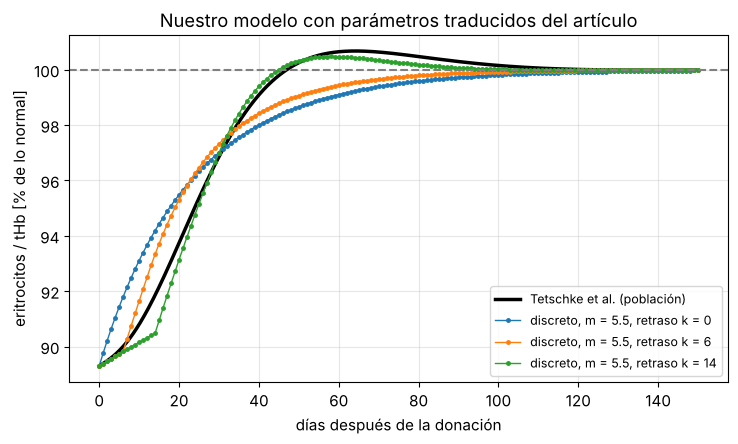

In [9]:
c = ALFA
b = 6 * c
G = 0.46 / (1.02 * K1)
m_tet = (1 + G) / (1 - c / b)
print(f"G = gamma / (beta k1) = {G:.2f}  ->  m = {m_tet:.2f}")
print(f"Estabilidad con k = 14: max|lambda| = {radio_espectral(c, beta_hill(m_tet), 14):.4f} (< 1: estable)")
m_critico = next(m for m in np.arange(1, 100, 0.1) if radio_espectral(c, beta_hill(m), 14) > 1)
print(f"Con k = 14 el equilibrio se vuelve inestable para m > {m_critico:.1f}")


def recuperacion_discreta(m, retraso, T=150):
    """Modelo discreto con Hill (exponente m) y retraso; pérdida de PERDIDA en el día 0."""
    p = lambda x: p2(x, b, theta_para_equilibrio_1(m), m)
    historia = np.ones(retraso + 1)
    historia[-1] = 1 - PERDIDA
    return iterar_con_retraso(c, p, retraso, historia, T)[retraso:]


t_ode, y_ode = recuperacion(1.02, 0.46)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(t_ode, 100 * y_ode, "k", lw=2.5, label="Tetschke et al. (población)")
print(f"\n{'Tetschke et al. (EDO, población)':38s}: 90 % del déficit en {dias_90(t_ode, y_ode):5.1f} días, máximo = {100 * y_ode.max():.2f} %")
for retraso in [0, 6, 14]:
    y = recuperacion_discreta(m_tet, retraso)
    dias = np.arange(len(y))
    ax.plot(dias, 100 * y, "o-", ms=2.5, lw=1, label=f"discreto, m = {m_tet:.1f}, retraso k = {retraso}")
    print(f"{'discreto, retraso k = ' + str(retraso):38s}: 90 % del déficit en {np.argmax(y >= 1 - 0.1 * PERDIDA):5d} días, máximo = {100 * y.max():.2f} %")
ax.axhline(100, color="gray", ls="--")
ax.set_xlabel("días después de la donación")
ax.set_ylabel("eritrocitos / tHb [% de lo normal]")
ax.set_title("Nuestro modelo con parámetros traducidos del artículo")
ax.legend(fontsize=9)
plt.show()

**Lectura.** Con los parámetros traducidos del artículo y el retraso de 14 días, nuestro modelo discreto de una sola variable reproduce bien lo esencial de la recuperación del modelo de tres compartimentos: el mismo tiempo de recuperación (unas 6 semanas) y un sobrepaso pequeño parecido. La forma al inicio sí difiere. Con un retraso **fijo**, durante las primeras dos semanas llegan células "encargadas" antes de la donación y la recuperación es casi plana; luego la respuesta llega de golpe. En los compartimentos, el retraso está **distribuido**: algunas células llegan antes y otras después, y la curva sube suavemente. Sin retraso, la recuperación empieza más rápido pero termina más lenta y sin sobrepaso. El retraso produce el sobrepaso porque la médula sigue respondiendo a un déficit de hace dos semanas, que era mayor que el actual.

Esto también conecta con la sección 3: con $m \approx 5.5$ y $k = 14$ estamos lejos de la región de oscilaciones sostenidas, que con este retraso empieza alrededor de $m \approx 17$ (mapa de estabilidad). Para que la regulación de una persona sana produjera oscilaciones, la respuesta a un déficit tendría que ser unas tres veces más fuerte de lo que estiman los datos.

**Limitaciones:** el valor $b = 6c$ es un supuesto nuestro (solo importa la pendiente de $p$ en el equilibrio, pero $m$ depende de $b$). Un retraso fijo de 14 días es más brusco que el retraso distribuido de los compartimentos, lo que favorece las oscilaciones. Y, como notan los propios autores, en varios sujetos el mínimo de tHb no ocurre justo después de la donación sino una semana después; ninguno de los dos modelos captura esa fase.

## Conclusiones

1. $a$ y $b$ (o $b$ en Hill) son la producción por célula en anemia extrema; $b$ en Ricker y $\theta$ en Hill fijan la escala de la población normal; $m$ fija qué tan abrupta es la regulación.
2. Hay un equilibrio positivo si la producción en anemia supera la destrucción. Es estable salvo que la regulación sea muy abrupta: $c\ln(a/c) > 2$ (Ricker) o $cm(1 - c/b) > 2$ (Hill) dan duplicaciones de periodo y caos. Con $c = 1/120$ esos umbrales son inalcanzables.
3. Un retraso de pocos días, en cambio, sí puede producir oscilaciones sostenidas (como en Mackey–Glass), sobre todo si aumenta la destrucción.
4. El modelo de Tetschke et al. sustituye la función $p(x)$ por tres compartimentos con una retroalimentación lineal sobre las células sensibles a la EPO, y ajusta dos parámetros por persona con datos de donadores. Traduciendo sus parámetros a nuestro modelo ($c = 1/120$, retraso de 14 días, $m \approx 5.5$), el modelo discreto reproduce bien su tiempo de recuperación de unas 6 semanas y su pequeño sobrepaso, aunque no la forma suave del inicio.

**Referencias:** de Vries et al. (2006), *A Course in Mathematical Biology*, SIAM, pp. 9–47; Mackey, M. & Glass, L. (1977), *Science* 197: 287–289; Tetschke, M. et al. (2018), *Processes* 6(9): 157, doi:10.3390/pr6090157; Pottgiesser, T. et al. (2008), *Transfusion* 48: 1390–1397.